# 03 - Optimisation des hyperparamètres et évaluation finale

Protocole :
1. **Grid Search** (modèles à peu d'hyperparamètres : régression logistique, k-NN, arbre, Naive Bayes) et **Random Search**
   (SVM, forêt, boosting), en **validation croisée stratifiée 5 plis** sur le train. Critère : **ROC-AUC** (indépendant du seuil).
   Le prétraitement (`std` / `log1p`) et la sélection (`none` / `vif`) font partie de l'espace de recherche.
2. Comparaison **coût / gain** Grid vs Random sur le SVM.
3. **Seuil de décision** réglé pour maximiser le F1 sur des prédictions hors-pli (train uniquement).
4. **Vote souple** (forêt + SVM + boosting + k-NN) construit à partir des modèles optimisés.
   **Règle de choix fixée avant le test** : le modèle final est celui qui a le meilleur F1 hors-pli (seuil optimal) parmi les modèles individuels et le vote.
5. **Une seule évaluation sur le jeu de test**, pour le modèle retenu.
6. Interprétation (importance par permutation) et export.

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from src.config import FIGURES_DIR, MODELS_DIR, RANDOM_STATE
from src.data import add_binary_target, drop_duplicate_wines, load_wine_data, split_data
from src.ensemble import ENSEMBLE_MEMBERS, build_voting_ensemble
from src.evaluate import (
    best_f1_threshold,
    compare_models,
    compute_metrics,
    default_cv,
    evaluate_at_threshold,
    get_scores,
    oof_scores,
    plot_confusion_matrices,
    plot_pr_curves,
    plot_roc_curves,
)
from src.models import build_model
from src.tuning import SPACES, best_params_readable, n_candidates, search_results, tune_model

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


df = drop_duplicate_wines(add_binary_target(load_wine_data()))
X_train, X_test, y_train, y_test = split_data(df)
cv = default_cv()
print(f"Train : {len(X_train)} | Test : {len(X_test)}")

Train : 4256 | Test : 1064


## 1. Recherche d'hyperparamètres

In [2]:
TUNED = [n for n in SPACES]
searches, summary = {}, []
for name in TUNED:
    t0 = time.perf_counter()
    s = tune_model(name, X_train, y_train, cv=cv)
    elapsed = time.perf_counter() - t0
    searches[name] = s
    summary.append({
        "modèle": name,
        "méthode": SPACES[name]["method"],
        "candidats": n_candidates(s),
        "durée (s)": round(elapsed, 1),
        "ROC-AUC CV": round(s.best_score_, 4),
        "meilleurs paramètres": best_params_readable(s),
    })
    print(f"{name:7s} {SPACES[name]['method']:6s} {n_candidates(s):4d} candidats  {elapsed:6.1f}s  AUC={s.best_score_:.4f}")
summary = pd.DataFrame(summary).set_index("modèle")
summary

logreg  grid     56 candidats     4.2s  AUC=0.8321


knn     grid    112 candidats     3.7s  AUC=0.8448


tree    grid    192 candidats     2.8s  AUC=0.7982


nb      grid     28 candidats     0.4s  AUC=0.7802


svm     random   40 candidats     4.9s  AUC=0.8469


rf      random   30 candidats    23.3s  AUC=0.8551


gb      random   30 candidats    18.1s  AUC=0.8527


,méthode,candidats,durée (s),ROC-AUC CV,meilleurs paramètres
modèle,,,,,
logreg,grid,56,4.2,0.8321,"{'C': 1, 'class_weight': None, 'prep': 'log1p', 'select': 'none'}"
knn,grid,112,3.7,0.8448,"{'n_neighbors': 41, 'p': 1, 'weights': 'distance', 'prep': 'std', 'select': 'vif'}"
tree,grid,192,2.8,0.7982,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20, 'prep': 'std', 'selec..."
nb,grid,28,0.4,0.7802,"{'var_smoothing': 0.001, 'prep': 'log1p', 'select': 'vif'}"
svm,random,40,4.9,0.8469,"{'C': 1.5326772391384107, 'class_weight': 'balanced', 'gamma': 0.062187047277690755, '..."
rf,random,30,23.3,0.8551,"{'select': 'none', 'prep': 'std', 'n_estimators': 600, 'min_samples_leaf': 3, 'max_fea..."
gb,random,30,18.1,0.8527,"{'learning_rate': 0.02028406763400795, 'max_depth': 5, 'min_samples_leaf': 18, 'n_esti..."


**Lecture** :
- Meilleurs ROC-AUC en CV : forêt (0,855), boosting (0,853), SVM (0,847), k-NN (0,845), régression logistique (0,832), arbre (0,798),
  Naive Bayes (0,780). Les quatre premiers sont séparés de moins de 0,01, soit moins que l'écart-type entre plis (≈ 0,01 à 0,015).
- Réglages gagnants : k-NN avec **k = 41, distance de Manhattan, vote pondéré par la distance** (k grand = faible variance, cohérent avec la
  courbe de complexité de l'étape précédente) ; SVM avec C ≈ 1,5 et gamma ≈ 0,06 (classes pondérées) ; forêt de 600 arbres,
  `min_samples_leaf = 3`, `max_features = log2` ; boosting avec un faible taux d'apprentissage (≈ 0,02) et des arbres de profondeur 5.
- Les choix structurels (`std` / `log1p`, `none` / `vif`) ont peu d'effet : la régression logistique et Naive Bayes préfèrent `log1p`
  (variables plus proches d'une loi symétrique), le reste est indifférent. La suppression de `density` par le VIF ne coûte rien.

In [3]:
# Top 5 des configurations pour chaque modèle
for name in TUNED:
    print(f"\n=== {name} ===")
    cols = [c for c in search_results(searches[name]).columns if not c.endswith("_std") and c not in ("fit_time", "recall_mean", "precision_mean")]
    display(search_results(searches[name], top=5)[cols].round(4))


=== logreg ===


,prep,select,C,class_weight,roc_auc_mean,average_precision_mean,f1_mean,rank
0,log1p,none,1.0,NaN,0.8321,0.5208,0.3945,1
1,log1p,none,3.0,NaN,0.8319,0.5208,0.3964,2
2,log1p,none,10.0,NaN,0.8319,0.5209,0.3974,3
3,log1p,none,0.3,NaN,0.8318,0.5204,0.3929,4
4,log1p,none,1.0,balanced,0.8315,0.5156,0.5377,5



=== knn ===


,prep,select,n_neighbors,weights,p,roc_auc_mean,average_precision_mean,f1_mean,rank
0,std,vif,41,distance,1,0.8448,0.5678,0.4136,1
1,log1p,vif,41,distance,1,0.8436,0.5649,0.4047,2
2,std,vif,25,distance,1,0.8435,0.5745,0.4441,3
3,log1p,none,41,distance,1,0.8434,0.5627,0.4221,4
4,log1p,vif,61,distance,1,0.8432,0.5640,0.3716,5



=== tree ===


,prep,select,max_depth,min_samples_leaf,criterion,roc_auc_mean,average_precision_mean,f1_mean,rank
0,std,none,5.0,20,entropy,0.7982,0.4434,0.4947,1
1,log1p,none,5.0,20,entropy,0.7977,0.4432,0.4947,2
2,log1p,vif,5.0,20,entropy,0.7976,0.4431,0.4954,3
3,std,vif,5.0,20,entropy,0.7971,0.4429,0.4954,4
4,log1p,vif,5.0,5,entropy,0.7965,0.4431,0.4978,5


... (4 outputs left out)


=== rf ===


,prep,select,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,roc_auc_mean,average_precision_mean,f1_mean,rank
0,std,none,600,24.0,3,log2,balanced,0.8551,0.5876,0.5710,1
1,std,vif,400,24.0,3,log2,balanced_subsample,0.8549,0.5824,0.5406,2
2,std,vif,600,NaN,3,0.5,balanced_subsample,0.8540,0.5854,0.5467,3
3,std,vif,400,24.0,5,0.5,balanced,0.8538,0.5822,0.5589,4
4,log1p,none,400,NaN,5,sqrt,balanced_subsample,0.8538,0.5785,0.5525,5



=== gb ===


,prep,select,n_estimators,learning_rate,max_depth,subsample,min_samples_leaf,roc_auc_mean,average_precision_mean,f1_mean,rank
0,log1p,vif,317,0.0203,5,0.8,18,0.8527,0.5700,0.4656,1
1,std,none,336,0.0117,5,0.8,16,0.8497,0.5633,0.4548,2
2,log1p,vif,443,0.0129,4,0.6,9,0.8494,0.5641,0.4438,3
3,log1p,none,279,0.0229,4,0.6,9,0.8493,0.5601,0.4398,4
4,std,none,289,0.0301,4,0.6,7,0.8478,0.5580,0.4562,5


Les cinq meilleures configurations de chaque modèle sont **très proches** (écarts de l'ordre de 0,001 sur l'AUC) : la surface de
performance est un **plateau**, pas un pic étroit. Les résultats sont donc peu sensibles au réglage fin des hyperparamètres.
Pour la régression logistique, la version non pondérée arrive en tête sur l'AUC mais avec un F1 de 0,39 au seuil 0,5 : l'AUC ne dépend pas
du seuil, d'où l'intérêt de régler ce dernier séparément (étape 4).

## 2. Grid Search vs Random Search : coût et gain (SVM)

In [4]:
base = build_model("svm")
C_grid = [0.1, 0.3, 1, 3, 10, 30, 100]
gamma_grid = [0.003, 0.01, 0.03, 0.1, 0.3]
common = dict(scoring="roc_auc", cv=cv, n_jobs=-1)

rows = []
t0 = time.perf_counter()
g = GridSearchCV(base, {"clf__C": C_grid, "clf__gamma": gamma_grid}, **common).fit(X_train, y_train)
rows.append({"méthode": "Grid 7x5", "candidats": n_candidates(g), "durée (s)": time.perf_counter() - t0, "ROC-AUC CV": g.best_score_})

dist = {"clf__C": loguniform(0.1, 100), "clf__gamma": loguniform(0.003, 0.3)}
for n_iter in (10, 20, 35):
    t0 = time.perf_counter()
    r = RandomizedSearchCV(base, dist, n_iter=n_iter, random_state=RANDOM_STATE, **common).fit(X_train, y_train)
    rows.append({"méthode": f"Random {n_iter}", "candidats": n_candidates(r), "durée (s)": time.perf_counter() - t0, "ROC-AUC CV": r.best_score_})
cmp = pd.DataFrame(rows).set_index("méthode")
cmp.round(4)

,candidats,durée (s),ROC-AUC CV
méthode,,,
Grid 7x5,35,3.9385,0.8467
Random 10,10,1.3441,0.8441
Random 20,20,2.2930,0.8465
Random 35,35,3.8930,0.8465


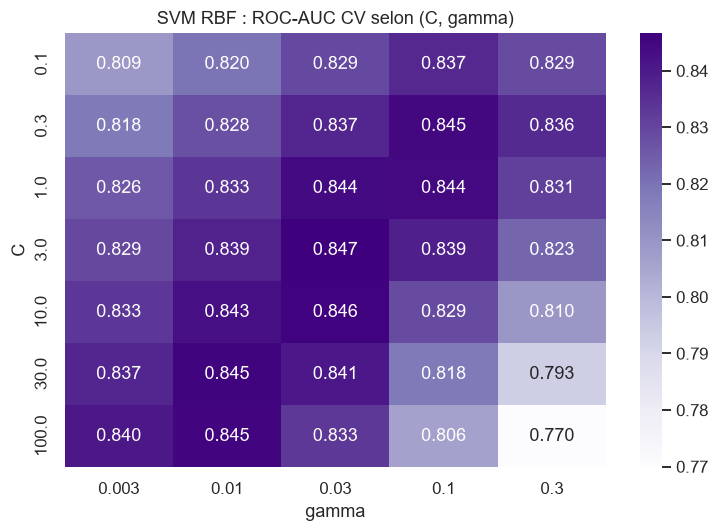

In [5]:
# Surface de score explorée par la grille
res = pd.DataFrame(g.cv_results_)
heat = res.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(heat.astype(float), annot=True, fmt=".3f", cmap="Purples", ax=ax)
ax.set(title="SVM RBF : ROC-AUC CV selon (C, gamma)", xlabel="gamma", ylabel="C")
plt.tight_layout()
save(fig, "15_svm_grid_heatmap")
plt.show()

**Coût / gain** :
- À budget égal (35 candidats), Grid et Random donnent le même résultat (ROC-AUC 0,8467 contre 0,8465, 3,9 s dans les deux cas).
- Avec **20 tirages**, le Random Search atteint 0,8465 en 2,3 s (**-42 % de temps** pour -0,0002 d'AUC). Avec 10 tirages, 1,3 s et 0,8441 :
  perte de 0,0026, inférieure à l'écart-type entre plis.
- La carte de chaleur montre une **crête diagonale** : un C élevé doit être compensé par un gamma faible (C ≈ 35 avec gamma ≈ 0,01 donne
  la même AUC que C ≈ 1,5 avec gamma ≈ 0,06). Le coin C grand / gamma grand (0,770) est le **sur-apprentissage** : frontière trop flexible et marge
  trop étroite ; le coin C petit / gamma petit (0,809) est le **sous-apprentissage**.
- Le coût d'une grille croît de façon **exponentielle** avec le nombre d'hyperparamètres, celui du Random Search est fixé par `n_iter`. C'est
  pourquoi la grille est réservée aux modèles à 1-3 hyperparamètres, et le Random Search au SVM, à la forêt et au boosting.

## 3. Gain par rapport aux réglages par défaut

In [6]:
default = compare_models(TUNED, X_train, y_train, cv=cv)
gain = pd.DataFrame({
    "AUC défaut": default["roc_auc_mean"],
    "AUC optimisé": pd.Series({n: s.best_score_ for n, s in searches.items()}),
    "F1 défaut": default["f1_mean"],
    "F1 optimisé (seuil 0,5)": pd.Series({n: s.cv_results_["mean_test_f1"][s.best_index_] for n, s in searches.items()}),
})
gain["gain AUC"] = gain["AUC optimisé"] - gain["AUC défaut"]
gain.round(4)

,AUC défaut,AUC optimisé,F1 défaut,"F1 optimisé (seuil 0,5)",gain AUC
logreg,0.8281,0.8321,0.5318,0.3945,0.0039
knn,0.7994,0.8448,0.4913,0.4136,0.0454
tree,0.6508,0.7982,0.4346,0.4947,0.1475
nb,0.7694,0.7802,0.4898,0.4956,0.0108
svm,0.8454,0.8469,0.5410,0.5395,0.0015
rf,0.8548,0.8551,0.5557,0.5710,0.0003
gb,0.8430,0.8527,0.4343,0.4656,0.0098


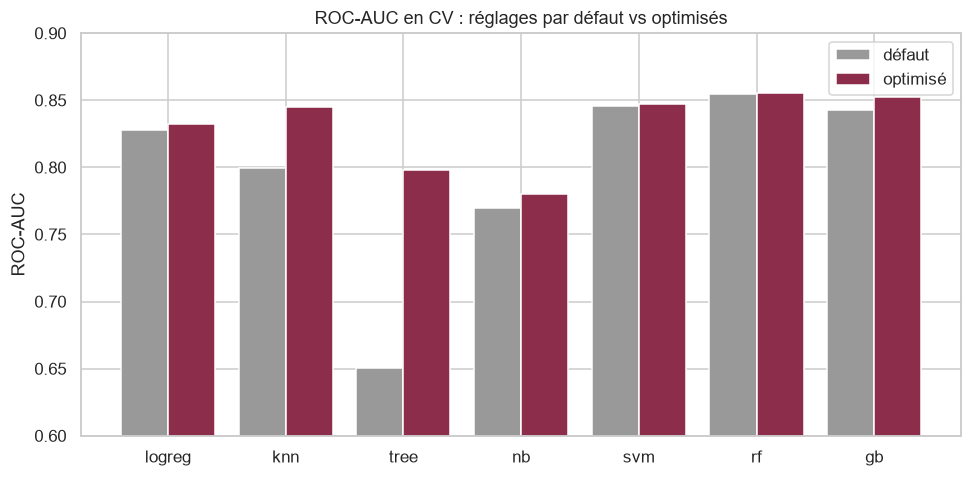

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(gain))
ax.bar(x - 0.2, gain["AUC défaut"], 0.4, label="défaut", color="#999999")
ax.bar(x + 0.2, gain["AUC optimisé"], 0.4, label="optimisé", color="#8c2d4b")
ax.set_xticks(x, gain.index)
ax.set_ylim(0.6, 0.9)
ax.set(title="ROC-AUC en CV : réglages par défaut vs optimisés", ylabel="ROC-AUC")
ax.legend()
plt.tight_layout()
save(fig, "16_tuning_gain")
plt.show()

**Gain de l'optimisation (ROC-AUC en CV)** :
- Gains importants pour les modèles **à forte variance ou sensibles à la géométrie** : arbre **+0,148** (0,651 → 0,798, grâce à
  `max_depth = 5` et `min_samples_leaf = 20`), k-NN **+0,045** (k = 41, Manhattan).
- Gains faibles pour boosting (+0,010), Naive Bayes (+0,011) et régression logistique (+0,004) ; quasi nuls pour le SVM (+0,0015) et la forêt
  (+0,0003), dont les réglages par défaut étaient déjà proches de l'optimum.
- Le plafond observé (AUC ≈ 0,85) tient à l'**information contenue dans les variables** (la note est subjective et les mesures
  physico-chimiques ne l'expliquent qu'en partie), et non au choix du modèle.
- Les estimations de la recherche sont légèrement optimistes (le meilleur candidat est choisi sur les mêmes plis) ; l'évaluation sur le test
  ci-dessous est la mesure non biaisée.

## 4. Seuil de décision (F1) sur prédictions hors-pli

In [8]:
best = {n: s.best_estimator_ for n, s in searches.items()}
oof = {}
rows = []
for name, est in best.items():
    scores, default_thr = oof_scores(est, X_train, y_train, cv=cv)
    thr = best_f1_threshold(y_train, scores)
    oof[name] = (scores, thr)
    at_default = compute_metrics(y_train, (scores >= default_thr).astype(int), scores)
    at_best = compute_metrics(y_train, (scores >= thr).astype(int), scores)
    rows.append({
        "modèle": name,
        "AUC": at_best["roc_auc"],
        "AP": at_best["average_precision"],
        "F1 (seuil défaut)": at_default["f1"],
        "seuil optimal": thr,
        "F1 (seuil optimal)": at_best["f1"],
        "précision": at_best["precision"],
        "rappel": at_best["recall"],
    })
thr_table = pd.DataFrame(rows).set_index("modèle").sort_values("F1 (seuil optimal)", ascending=False)
thr_table.round(3)

,AUC,AP,F1 (seuil défaut),seuil optimal,F1 (seuil optimal),précision,rappel
modèle,,,,,,,
rf,0.855,0.581,0.571,0.457,0.575,0.469,0.742
gb,0.852,0.562,0.466,0.264,0.574,0.483,0.708
svm,0.846,0.535,0.539,0.534,0.570,0.491,0.680
knn,0.844,0.560,0.414,0.289,0.554,0.451,0.717
logreg,0.831,0.510,0.394,0.230,0.551,0.441,0.735
tree,0.797,0.453,0.493,0.620,0.511,0.402,0.700
nb,0.780,0.461,0.496,0.419,0.504,0.408,0.660


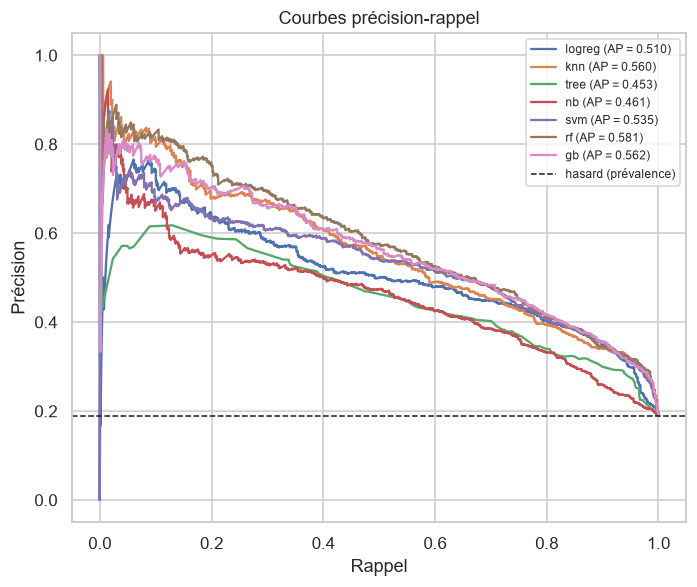

In [9]:
fig = plot_pr_curves(y_train, {n: s for n, (s, _) in oof.items()})
save(fig, "17_pr_curves_tuned")
plt.show()

**Lecture** :
- Le seuil ne modifie ni l'AUC ni l'AP, seulement le compromis précision / rappel. Il apporte un gain **important** aux modèles dont les scores
  ne sont pas calibrés pour des classes 80/20 : boosting (F1 0,466 → 0,574 avec un seuil de 0,26), k-NN (0,414 → 0,554) et régression
  logistique non pondérée (0,394 → 0,551). Il n'apporte presque rien à la forêt et au SVM, déjà pondérés par classe.
- Après réglage du seuil, les quatre meilleurs modèles individuels sont **pratiquement à égalité** (F1 de 0,554 à 0,575) : forêt, boosting, SVM et k-NN.
  La forêt est première à la fois sur l'AUC, l'AP et le F1 parmi les modèles individuels. Cette proximité justifie de les **combiner**
  (étape suivante).
- Le seuil et le F1 de ce tableau sont estimés sur les mêmes prédictions hors-pli : ils sont légèrement optimistes.

## 5. Vote souple des modèles optimisés

In [10]:
members = {n: best[n] for n in ENSEMBLE_MEMBERS}
vote = build_voting_ensemble(members)

# Scores hors-pli du vote (le vote est ré-entraîné dans chaque pli) puis seuil F1
vote_scores, vote_default = oof_scores(vote, X_train, y_train, cv=cv)
vote_thr = best_f1_threshold(y_train, vote_scores)
oof["vote"] = (vote_scores, vote_thr)

at_default = compute_metrics(y_train, (vote_scores >= vote_default).astype(int), vote_scores)
at_best = compute_metrics(y_train, (vote_scores >= vote_thr).astype(int), vote_scores)
vote_row = pd.DataFrame([{
    "modèle": "vote", "AUC": at_best["roc_auc"], "AP": at_best["average_precision"],
    "F1 (seuil défaut)": at_default["f1"], "seuil optimal": vote_thr, "F1 (seuil optimal)": at_best["f1"],
    "précision": at_best["precision"], "rappel": at_best["recall"],
}]).set_index("modèle")

candidates = pd.concat([thr_table, vote_row]).sort_values("F1 (seuil optimal)", ascending=False)
vote.fit(X_train, y_train)
best["vote"] = vote
candidates.round(3)

,AUC,AP,F1 (seuil défaut),seuil optimal,F1 (seuil optimal),précision,rappel
modèle,,,,,,,
vote,0.859,0.587,0.506,0.343,0.585,0.494,0.717
rf,0.855,0.581,0.571,0.457,0.575,0.469,0.742
gb,0.852,0.562,0.466,0.264,0.574,0.483,0.708
svm,0.846,0.535,0.539,0.534,0.570,0.491,0.680
knn,0.844,0.560,0.414,0.289,0.554,0.451,0.717
logreg,0.831,0.510,0.394,0.230,0.551,0.441,0.735
tree,0.797,0.453,0.493,0.620,0.511,0.402,0.700
nb,0.780,0.461,0.496,0.419,0.504,0.408,0.660


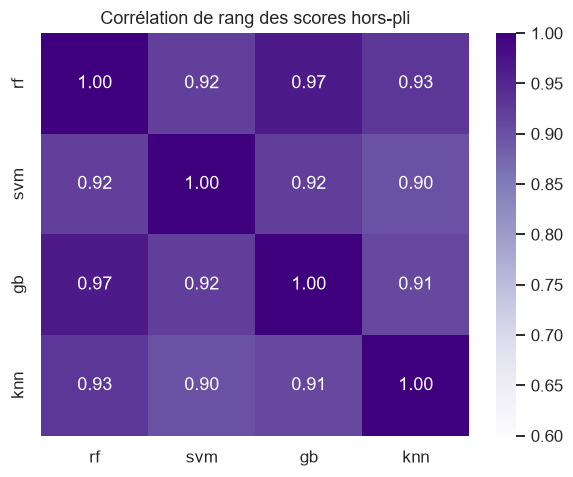

,rf,svm,gb,knn
rf,1.000,0.922,0.965,0.931
svm,0.922,1.000,0.923,0.900
gb,0.965,0.923,1.000,0.909
knn,0.931,0.900,0.909,1.000


In [11]:
# Diversité des membres : corrélation de rang entre leurs scores hors-pli
div = pd.DataFrame({n: oof[n][0] for n in ENSEMBLE_MEMBERS}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(div, annot=True, fmt=".2f", cmap="Purples", vmin=0.6, vmax=1, ax=ax)
ax.set_title("Corrélation de rang des scores hors-pli")
plt.tight_layout()
save(fig, "23_vote_member_correlation")
plt.show()
div.round(3)

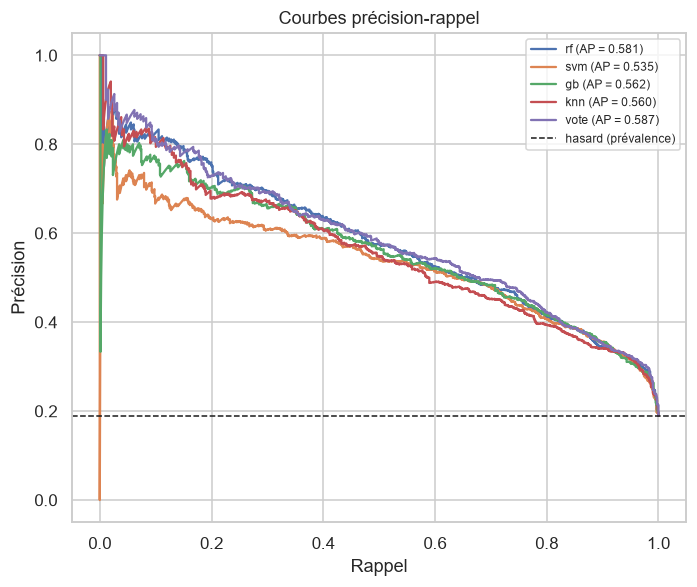

In [12]:
fig = plot_pr_curves(y_train, {n: oof[n][0] for n in ["rf", "svm", "gb", "knn", "vote"]})
save(fig, "24_pr_curves_vote")
plt.show()

**Lecture** :
- Le **vote souple** est en tête sur les trois indicateurs hors-pli : ROC-AUC **0,859** (forêt 0,855), AP **0,587** (0,581), F1 **0,585** (0,575),
  avec un seuil de 0,34 qui privilégie le rappel (0,72) au détriment de la précision (0,49). Selon la règle fixée au départ, il est **retenu**.
- Le gain est **faible** (+0,004 d'AUC, +0,010 de F1) : inférieur à l'écart-type entre plis (≈ 0,01). Il s'explique par une **diversité limitée** :
  les scores des membres sont fortement corrélés (corrélation de rang de 0,90 à 0,97 ; la plus faible entre k-NN et SVM, la plus forte entre forêt et
  boosting, deux modèles d'arbres). Plus les erreurs sont décorrélées, plus un vote est utile ; ici elles ne le sont que partiellement.
- Sur les courbes PR, le vote est très proche de la forêt et légèrement au-dessus pour un rappel d'environ 0,5 à 0,75. Le SVM seul est nettement
  plus bas pour les faibles rappels (précision ≈ 0,65 à 0,75 contre ≈ 0,8), ce qui explique son AP plus faible (0,535).

## 6. Évaluation finale sur le jeu de test (modèle retenu)

In [13]:
winner = candidates.index[0]
threshold = oof[winner][1]
model = best[winner]
print("Modèle retenu :", winner)
if winner != "vote":
    print("Paramètres    :", best_params_readable(searches[winner]))
print(f"Seuil F1      : {threshold:.4f}")

cols = {
    f"{winner} (seuil {threshold:.2f})": evaluate_at_threshold(model, X_test, y_test, threshold),
    f"{winner} (seuil 0,5)": evaluate_at_threshold(model, X_test, y_test, 0.5),
}
if winner != "rf":
    cols[f"forêt (seuil {oof['rf'][1]:.2f})"] = evaluate_at_threshold(best["rf"], X_test, y_test, oof["rf"][1])
test_table = pd.DataFrame(cols)
test_tuned = test_table.iloc[:, 0]
test_table.round(3)

Modèle retenu : vote
Seuil F1      : 0.3432


,vote (seuil 0.34),"vote (seuil 0,5)",forêt (seuil 0.46)
accuracy,0.812,0.854,0.798
precision,0.503,0.654,0.480
recall,0.728,0.495,0.757
f1,0.595,0.563,0.587
roc_auc,0.864,0.864,0.867
average_precision,0.618,0.618,0.628


**Test (1064 vins, environ 200 bons vins)** :
- Vote souple au seuil optimisé (0,34) : **ROC-AUC 0,864, AP 0,618, F1 0,595, rappel 0,728, précision 0,503**.
- Forêt, pour comparaison : ROC-AUC 0,867, AP 0,628, F1 0,587.
- Les résultats sont **cohérents avec la CV** (AUC 0,859, F1 0,585) : pas de sur-ajustement au protocole de validation.
- Le seuil compte pour le vote : à 0,5 le F1 tombe à 0,563 (rappel 0,495, précision 0,654). Le seuil optimisé en CV a donc bien transféré sur le test.

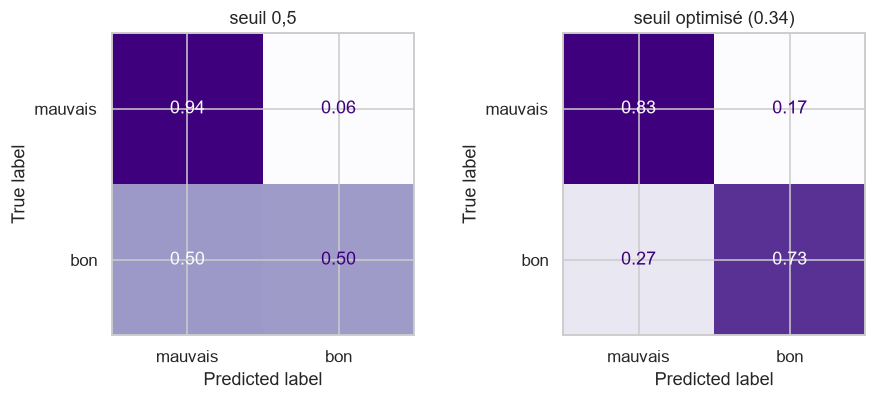

,"CV (hors-pli, train)",Test
ROC-AUC,0.859,0.864
AP,0.587,0.618
F1,0.585,0.595
précision,0.494,0.503
rappel,0.717,0.728


In [14]:
s_test = get_scores(model, X_test)
fig = plot_confusion_matrices(
    y_test,
    {"seuil 0,5": (s_test >= 0.5).astype(int), f"seuil optimisé ({threshold:.2f})": (s_test >= threshold).astype(int)},
    normalize="true", ncols=2,
)
save(fig, "18_test_confusion")
plt.show()

cv_vs_test = pd.DataFrame({
    "CV (hors-pli, train)": candidates.loc[winner, ["AUC", "AP", "F1 (seuil optimal)", "précision", "rappel"]].values,
    "Test": [test_tuned["roc_auc"], test_tuned["average_precision"], test_tuned["f1"], test_tuned["precision"], test_tuned["recall"]],
}, index=["ROC-AUC", "AP", "F1", "précision", "rappel"])
cv_vs_test.round(3)

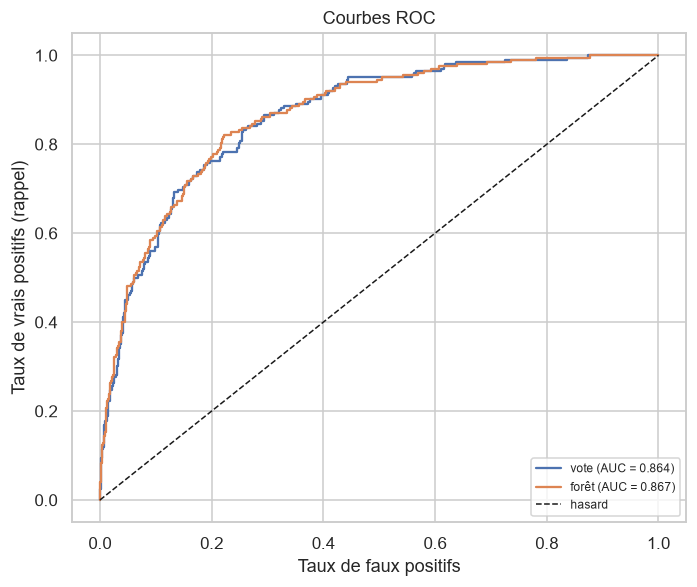

In [15]:
fig = plot_roc_curves(y_test, {winner: s_test, **({"forêt": get_scores(best["rf"], X_test)} if winner != "rf" else {})})
save(fig, "19_test_roc")
plt.show()

In [16]:
# Incertitude : bootstrap apparié du test (mêmes vins pour les deux modèles, seuils fixés)
rng = np.random.default_rng(RANDOM_STATE)
y = y_test.to_numpy()
s_rf = get_scores(best["rf"], X_test)
p_win, p_rf = (s_test >= threshold).astype(int), (s_rf >= oof["rf"][1]).astype(int)
boot = {k: [] for k in ("auc_w", "auc_rf", "f1_w", "f1_rf")}
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    if y[idx].min() == y[idx].max():
        continue
    boot["auc_w"].append(roc_auc_score(y[idx], s_test[idx]))
    boot["auc_rf"].append(roc_auc_score(y[idx], s_rf[idx]))
    boot["f1_w"].append(f1_score(y[idx], p_win[idx]))
    boot["f1_rf"].append(f1_score(y[idx], p_rf[idx]))
boot = pd.DataFrame(boot)

def ci(s):
    return f"{s.mean():.3f}  [{s.quantile(0.025):.3f} ; {s.quantile(0.975):.3f}]"

pd.DataFrame({
    winner: [ci(boot.auc_w), ci(boot.f1_w)],
    "forêt": [ci(boot.auc_rf), ci(boot.f1_rf)],
    f"différence ({winner} - forêt)": [ci(boot.auc_w - boot.auc_rf), ci(boot.f1_w - boot.f1_rf)],
}, index=["ROC-AUC", "F1"])

,vote,forêt,différence (vote - forêt)
ROC-AUC,0.864 [0.839 ; 0.891],0.867 [0.841 ; 0.893],-0.002 [-0.008 ; 0.003]
F1,0.595 [0.543 ; 0.643],0.587 [0.537 ; 0.636],0.008 [-0.015 ; 0.030]


Intervalles de confiance à 95 % (2000 rééchantillonnages du test). L'IC de la **différence appariée** inclut 0 pour les deux indicateurs
(AUC : [-0,008 ; +0,003] ; F1 : [-0,015 ; +0,030]) : **sur le test, le vote et la forêt ne sont pas statistiquement distinguables**. Le vote est un peu
meilleur en F1 et un peu moins bon en AUC et en AP, sans que l'écart soit significatif.
Le vote est retenu par la règle définie avant le test (meilleurs scores hors-pli), pour sa **stabilité** : il moyenne quatre modèles et dépend
moins d'un seul réglage, ce qui est un argument de robustesse plutôt que de performance.

## 7. Interprétation : importance des variables (permutation)

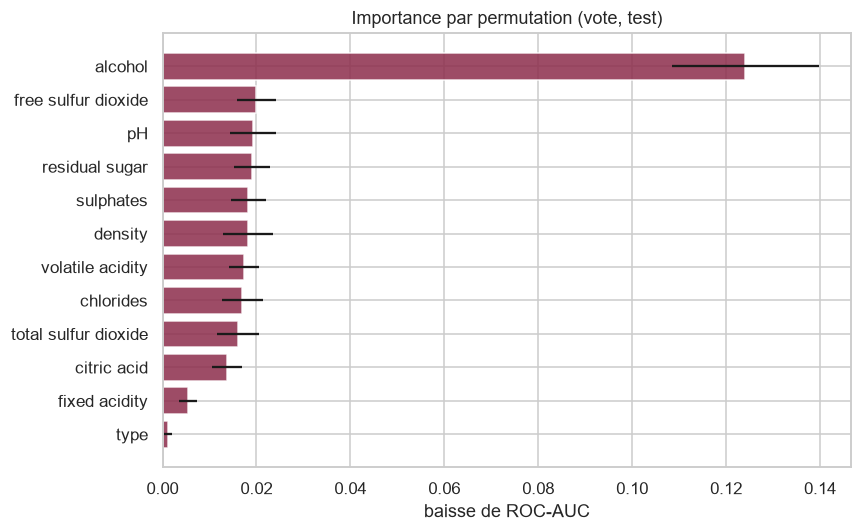

,importance,std
alcohol,0.1241,0.0156
free sulfur dioxide,0.0200,0.0041
pH,0.0193,0.0048
residual sugar,0.0191,0.0039
sulphates,0.0182,0.0037
density,0.0182,0.0054
volatile acidity,0.0174,0.0032
chlorides,0.0170,0.0044
total sulfur dioxide,0.0160,0.0045
citric acid,0.0137,0.0031


In [17]:
imp = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({"importance": imp.importances_mean, "std": imp.importances_std}, index=X_test.columns).sort_values("importance")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df.index, imp_df["importance"], xerr=imp_df["std"], color="#8c2d4b", alpha=0.85)
ax.set(title=f"Importance par permutation ({winner}, test)", xlabel="baisse de ROC-AUC")
plt.tight_layout()
save(fig, "20_permutation_importance")
plt.show()
imp_df.sort_values("importance", ascending=False).round(4)

**Interprétation** : `alcohol` domine nettement (perte de 0,124 d'AUC lorsqu'on permute sa colonne). Les autres variables se situent entre 0,014 et 0,020,
presque à égalité, sauf `fixed acidity` et `type`, négligeables. Le vote répartit l'importance plus uniformément qu'une forêt seule, car ses membres
(k-NN, SVM, forêt, boosting) s'appuient sur des variables différentes. Le résultat confirme l'EDA : l'alcool est le principal discriminant.
`density` apparaît moins importante qu'en EDA, car elle partage son information avec `alcohol` et `residual sugar` : la permutation répartit l'importance
entre variables corrélées.

## 8. Export

In [18]:
artifact = {
    "model": model, "threshold": float(threshold), "name": winner, "features": list(X_train.columns),
    "members": list(ENSEMBLE_MEMBERS) if winner == "vote" else [winner],
}
joblib.dump(artifact, MODELS_DIR / "wine_model.joblib")
print("Modèle exporté :", MODELS_DIR / "wine_model.joblib")

Modèle exporté : C:\Users\juvenis.kabore\Documents\Efrei Resources\Wine Quality Classification\models\wine_model.joblib


## 9. Synthèse

| Question | Réponse |
|---|---|
| Modèle final | **Vote souple** : forêt + SVM (calibré) + boosting + k-NN, hyperparamètres optimisés, seuil F1 = 0,34 |
| Performance sur le test | ROC-AUC **0,864**, AP 0,618, F1 **0,595**, rappel 0,728, précision 0,503 |
| Comparaison avec la forêt seule | Écart non significatif sur le test (IC95 % de la différence incluant 0) ; vote meilleur en CV (+0,004 AUC, +0,010 F1) |
| Effet de l'optimisation | Majeur pour l'arbre (+0,148 d'AUC) et k-NN (+0,045), faible ailleurs : plateau d'environ 0,85 |
| Grid vs Random | Même qualité à budget égal ; Random 20 tirages = -42 % de temps pour -0,0002 d'AUC |
| Seuil de décision | Utile pour boosting, k-NN, régression logistique et le vote ; neutre pour la forêt |
| Variable la plus importante | `alcohol`, très loin devant les autres |
| Limites | Précision d'environ 0,50 ; labels subjectifs ; diversité limitée entre membres (corrélation de rang 0,90-0,97) ; AUC plafonnée par l'information des variables |